# **CS 5361/6361 Machine Learning**

# **Logistic Regression**

**Author:** [Olac Fuentes](http://www.cs.utep.edu/ofuentes/)<br>
**Last modified:** 4/1/2026<br>

# Introduction



Logistic regression implements the function

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

$$ z = x \cdot w + b$$


where $x$ is a vector encoding a sample, $w$ is a weight vector of the same length as $x$, $b$ is a bias scalar, and $\sigma$ is known as the logistic function.

Recall that for vectors $x$ and $w$ of length $n$,

$$ x \cdot w = x_0w_0 + x_1*w_1 + \cdots + x_{n-1}*w_{n-1}$$

The following code cell shows a plot of the logistic function. Since it ranges from 0 to 1, it is often used to approximate probabilities.

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix
import time
from sklearn.linear_model import LogisticRegression

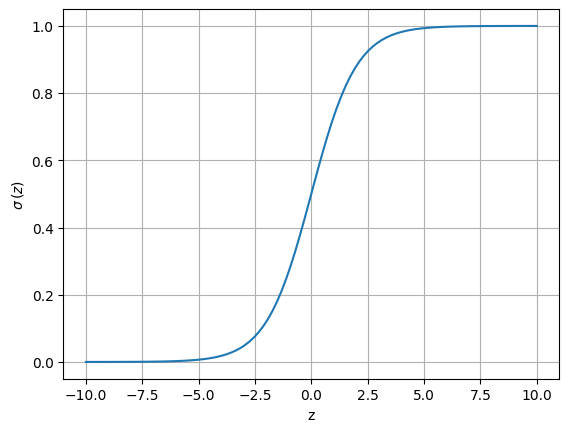

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10,10,100)
plt.figure()
plt.plot(z,sigmoid(z))
plt.xlabel('z')
plt.ylabel(r'$\sigma \, (z)$')
plt.grid(True)
plt.show()

Since logistic regression is a classification algorithm, the final prediction is given by:
$$ pred(x) = \begin{cases}
      1 & \sigma (z) \geq \frac{1}{2} \\
      0  & \sigma (z) <  \frac{1}{2}
   \end{cases} $$

Recall that in linear regression, $$ pred(x) = z = x \cdot w + b$$.

Just as in linear regression, in logistic regression $w$ and $b$ are found by optimizing a loss function on training data.

## Classifying a synthetic dataset

See documentation here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

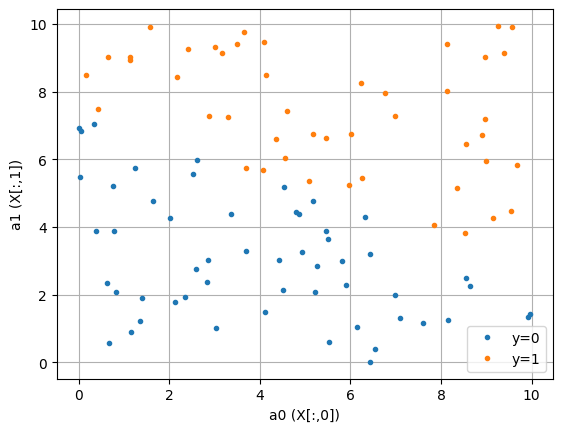

In [ ]:
X = np.random.random(size = (100,2))*10
y = np.int16((X[:,0] + 2*X[:,1] - 15)>0)

plt.figure()
for i in range(2):
  ind = y==i
  plt.plot(X[ind,0],X[ind,1],'.',label="y="+str(i))
plt.legend()
plt.grid(True)
plt.xlabel("a0 (X[:,0])")
plt.ylabel("a1 (X[:,1])")
plt.show()

Elapsed time training= 0.04 secs
Accuracy on training set 1.0


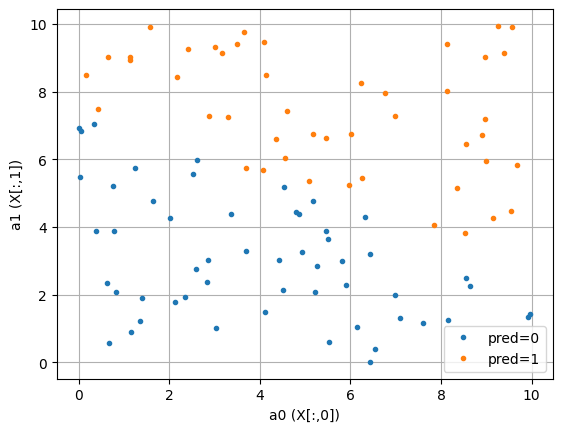

In [ ]:
model = LogisticRegression()
start_train = time.time()
model.fit(X,y)
end_train = time.time()
print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
pred = model.predict(X)
accuracy = accuracy_score(y, pred)
print(f'Accuracy on training set {accuracy:.4}')

plt.figure()
for i in range(2):
  ind = pred==i
  plt.plot(X[ind,0],X[ind,1],'.',label="pred="+str(i))
plt.legend()
plt.grid(True)
plt.xlabel("a0 (X[:,0])")
plt.ylabel("a1 (X[:,1])")
plt.show()

In [ ]:
w = model.coef_
print(w.shape)
b = model.intercept_
print(b.shape)
print(w)
print(b)

(1, 2)
(1,)
[[1.19793871 2.4153561 ]]
[-18.34148214]


In [ ]:
for C in [10, 1,.1,.01]:
  print('C =',C)
  model = LogisticRegression(C = C, tol=1e-6,  max_iter=int(1e6),solver = 'newton-cg')
  start_train = time.time()
  model.fit(X,y)
  end_train = time.time()
  print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
  pred = model.predict(X)
  accuracy = accuracy_score(y, pred)
  print(f'Accuracy on training set {accuracy:.4}')

  w = model.coef_
  b = model.intercept_
  print(w)
  print(b)

C = 10
Elapsed time training= 0.02 secs
Accuracy on training set 1.0
[[2.5879951  5.38870566]]
[-40.34999232]
C = 1
Elapsed time training= 0.01 secs
Accuracy on training set 1.0
[[1.19783629 2.41529256]]
[-18.3406708]
C = 0.1
Elapsed time training= 0.00 secs
Accuracy on training set 0.99
[[0.50674591 1.09746979]]
[-8.24650545]
C = 0.01
Elapsed time training= 0.00 secs
Accuracy on training set 0.95
[[0.16471725 0.42532891]]
[-3.12691177]


## Classifying the MNIST dataset

For multiple classes, we replace the sigmoid function by the softmax function:

$$ softmax(\mathbf{z})_i = \frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}} \quad \text{for } i = 1, \dotsc, K $$




In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = np.float32(x_train/255).reshape(x_train.shape[0],-1)
x_test = np.float32(x_test/255).reshape(x_test.shape[0],-1)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model = LogisticRegression()
start_train = time.time()
model.fit(x_train,y_train)
end_train = time.time()
print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
pred = model.predict(x_train)
accuracy = accuracy_score(y_train, pred)
print(f'Accuracy on training set {accuracy:.4}')
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy on test set {accuracy:.4}')
print(confusion_matrix(y_test, pred))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Elapsed time training= 40.51 secs
Accuracy on training set 0.9346
Accuracy on test set 0.9256
[[ 959    0    0    3    1    7    5    4    1    0]
 [   0 1112    4    2    0    2    3    2   10    0]
 [   6    9  928   16    8    4   15    7   35    4]
 [   4    1   17  921    0   23    4   11   23    6]
 [   1    1    7    4  914    0   10    4   10   31]
 [  10    2    3   37    8  779   14    5   29    5]
 [   9    3    7    3    8   15  910    2    1    0]
 [   1    9   23    6    7    1    0  950    2   29]
 [   9   10    8   26    8   26   12    7  857   11]
 [   9    8    0   11   23    6    0   19    7  926]]


Visualizing what the model learned

In [ ]:
w = model.coef_
print(w.shape)
b = model.intercept_
print(b.shape)

(10, 784)
(10,)


In [ ]:
x_test.shape

(10000, 784)

In [ ]:
pred = model.predict(x_test)
print(pred.shape)
print(pred[0])

(10000,)
7


In [ ]:
pred = model.predict_proba(x_test)
print(pred.shape)
print(pred[0].shape)
print(pred[0])

(10000, 10)
(10,)
[0.     0.     0.     0.0019 0.     0.     0.     0.9978 0.     0.0003]


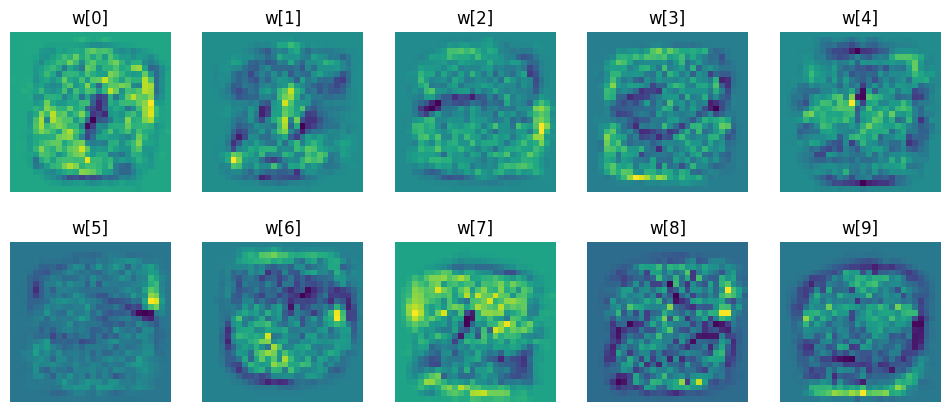

In [ ]:
fig, ax = plt.subplots(2, 5, figsize=(12,5))
for i in range(w.shape[0]):
  ax[i//5,i%5].imshow(w[i].reshape(28,28))
  ax[i//5,i%5].set_title(f'w[{i}]')
  ax[i//5,i%5].set_axis_off()


In [ ]:
pred[:10]

array([7, 2, 1, 0, 4, 1, 4, 9, 6, 9], dtype=uint8)

Since logistic regression outputs a probability distribution, we can also predict the probability of every class for every test example.

In [ ]:
pred_prob = model.predict_proba(x_test)
pred = np.argmax(pred_prob,axis=1)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy on test set {accuracy:.4}')
print(confusion_matrix(y_test, pred))

Accuracy on test set 0.9256
[[ 959    0    0    3    1    7    5    4    1    0]
 [   0 1112    4    2    0    2    3    2   10    0]
 [   6    9  928   16    8    4   15    7   35    4]
 [   4    1   17  921    0   23    4   11   23    6]
 [   1    1    7    4  914    0   10    4   10   31]
 [  10    2    3   37    8  779   14    5   29    5]
 [   9    3    7    3    8   15  910    2    1    0]
 [   1    9   23    6    7    1    0  950    2   29]
 [   9   10    8   26    8   26   12    7  857   11]
 [   9    8    0   11   23    6    0   19    7  926]]


In [ ]:
np.set_printoptions(precision = 4,linewidth =140,suppress=True)
print(pred_prob[:10])

[[0.     0.     0.     0.0019 0.     0.     0.     0.9978 0.     0.0003]
 [0.0003 0.     0.9944 0.0012 0.     0.0016 0.0023 0.     0.0002 0.    ]
 [0.     0.9875 0.0077 0.001  0.0001 0.0006 0.0004 0.001  0.0016 0.0001]
 [0.9999 0.     0.     0.     0.     0.     0.0001 0.     0.     0.    ]
 [0.0005 0.     0.0016 0.     0.9754 0.0001 0.0015 0.0021 0.001  0.0179]
 [0.     0.9919 0.0021 0.0008 0.     0.     0.     0.0035 0.0014 0.0002]
 [0.     0.     0.     0.     0.9926 0.0013 0.     0.0007 0.0023 0.0029]
 [0.     0.0174 0.0001 0.0002 0.0028 0.0016 0.     0.0003 0.0011 0.9765]
 [0.0003 0.     0.     0.     0.0003 0.0005 0.9989 0.     0.0001 0.    ]
 [0.     0.     0.     0.     0.0174 0.     0.     0.0206 0.0013 0.9606]]


In [ ]:
y_test[:10]

array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9], dtype=uint8)

Using quadratic features

In [ ]:
model2 = LogisticRegression(n_jobs=-1)
start_train = time.time()
model2.fit(np.hstack((x_train,x_train**2)),y_train)
end_train = time.time()
print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
pred = model2.predict(np.hstack((x_train,x_train**2)))
accuracy = accuracy_score(y_train, pred)
print(f'Accuracy on training set {accuracy:.4}')
pred = model2.predict(np.hstack((x_test,x_test**2)))
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy on test set {accuracy:.4}')
print(confusion_matrix(y_test, pred))

Elapsed time training= 54.37 secs
Accuracy on training set 0.9446
Accuracy on test set 0.9319
[[ 957    0    0    3    2    5    6    4    3    0]
 [   0 1119    4    1    0    3    3    1    4    0]
 [   5    7  941   13    8    4   11   11   29    3]
 [   4    0   17  928    2   20    3   12   17    7]
 [   1    1    7    3  915    0    8    9    8   30]
 [  11    2    6   36    9  772   14    8   26    8]
 [   8    3    9    0    7   16  909    2    4    0]
 [   1    7   24    4    8    2    0  952    2   28]
 [  10    7    6   19    6   11   11    6  890    8]
 [   5    9    0   13   18    7    0   16    5  936]]


In [ ]:
w = model2.coef_
print(w.shape)
b = model2.intercept_
print(b.shape)

(10, 1568)
(10,)


Coefficientes of linear features

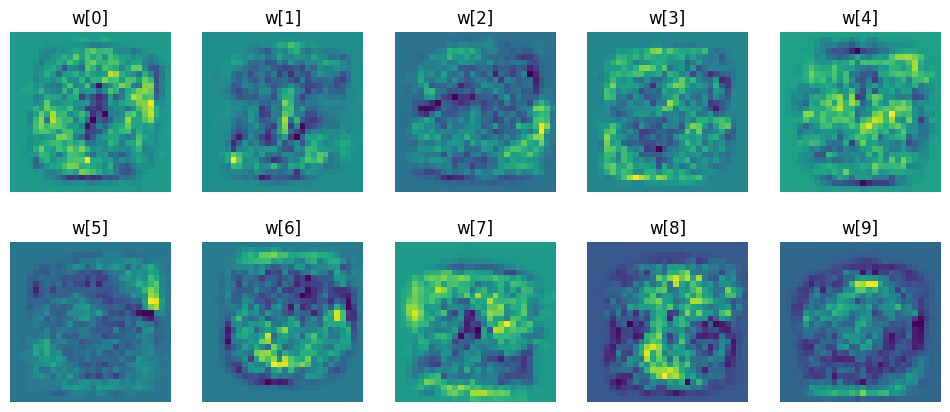

In [ ]:
fig, ax = plt.subplots(2, 5, figsize=(12,5))
for i in range(w.shape[0]):
  ax[i//5,i%5].imshow(w[i,:784].reshape(28,28))
  ax[i//5,i%5].set_title(f'w[{i}]')
  ax[i//5,i%5].set_axis_off()

Coefficientes of quadratic features

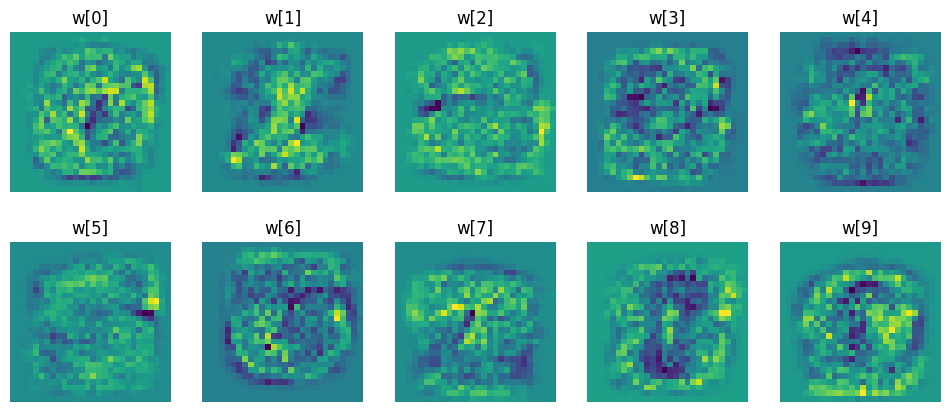

In [ ]:
fig, ax = plt.subplots(2, 5, figsize=(12,5))
for i in range(w.shape[0]):
  ax[i//5,i%5].imshow(w[i,784:].reshape(28,28))
  ax[i//5,i%5].set_title(f'w[{i}]')
  ax[i//5,i%5].set_axis_off()

# **Exercise:**
Implement the predict and predict_proba functions for multiclass logistic regression given the model's weights and biases.

In [ ]:
model = LogisticRegression()
start_train = time.time()
model.fit(x_train,y_train)
end_train = time.time()
print('Elapsed time training= {:.2f} secs'.format(end_train-start_train))
pred = model.predict(x_train)
accuracy = accuracy_score(y_train, pred)
print(f'Accuracy on training set {accuracy:.4}')
pred = model.predict(x_test)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy on test set {accuracy:.4}')
print(confusion_matrix(y_test, pred))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Elapsed time training= 60.01 secs
Accuracy on training set 0.9346
Accuracy on test set 0.9256
[[ 959    0    0    3    1    7    5    4    1    0]
 [   0 1112    4    2    0    2    3    2   10    0]
 [   6    9  928   16    8    4   15    7   35    4]
 [   4    1   17  921    0   23    4   11   23    6]
 [   1    1    7    4  914    0   10    4   10   31]
 [  10    2    3   37    8  779   14    5   29    5]
 [   9    3    7    3    8   15  910    2    1    0]
 [   1    9   23    6    7    1    0  950    2   29]
 [   9   10    8   26    8   26   12    7  857   11]
 [   9    8    0   11   23    6    0   19    7  926]]


In [ ]:
w = model.coef_
print(w.shape)
b = model.intercept_
print(b.shape)


(10, 784)
(10,)


In [ ]:
def softmax(z):
  z = np.exp(z)
  #return z/np.sum(z,axis=1,keepdims=True)
  return z/np.sum(z,axis=1).reshape(-1,1)

def predict_proba(X,W,b): # Returns array of shape (10000,10)
  z = np.matmul(X,W.T) + b
  return softmax(z)

def predict(X,W,b): # Returns array of shape (10000,)
  return np.argmax(predict_proba(X,W,b),axis=1)


p = predict_proba(x_test,w,b)


In [ ]:
p[0]

array([0.    , 0.    , 0.    , 0.0019, 0.    , 0.    , 0.    , 0.9978, 0.    , 0.0003])

In [ ]:
pred = predict(x_test,w,b)
accuracy = accuracy_score(y_test, pred)
print(f'Accuracy on test set {accuracy:.4}')
print(confusion_matrix(y_test, pred))

Accuracy on test set 0.9256
[[ 959    0    0    3    1    7    5    4    1    0]
 [   0 1112    4    2    0    2    3    2   10    0]
 [   6    9  928   16    8    4   15    7   35    4]
 [   4    1   17  921    0   23    4   11   23    6]
 [   1    1    7    4  914    0   10    4   10   31]
 [  10    2    3   37    8  779   14    5   29    5]
 [   9    3    7    3    8   15  910    2    1    0]
 [   1    9   23    6    7    1    0  950    2   29]
 [   9   10    8   26    8   26   12    7  857   11]
 [   9    8    0   11   23    6    0   19    7  926]]
